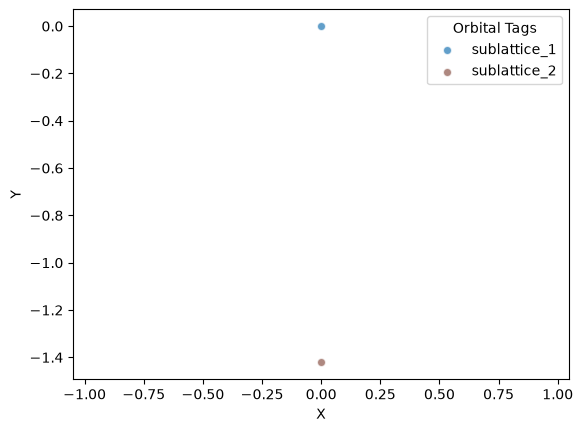

In [1]:
import matplotlib.pyplot as plt
from granad import *

graphene = get_graphene()
flake = graphene.cut_flake(grid_range = [(0,1), (0,2)])
del flake[1]
del flake[-1]
flake.show_2d()

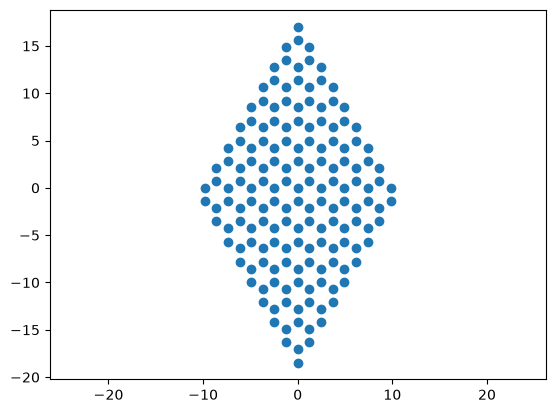

In [2]:
lattice_vectors = 2.46 * jnp.array([
    [1/2, -jnp.sqrt(3)/2, 0],
    [1/2, jnp.sqrt(3)/2, 0]
])

fourier_cutoff = 1
bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
bulk.show_2d(4)

In [3]:

### Band Structures

# We can plot graphene's band structure along its high-symmetry path by assessing the reciprocal lattice vectors, 
# which are computed as a property of the bulk

A, B = bulk.reciprocal_basis.T

A_norm = jnp.linalg.norm(A)
B_norm = jnp.linalg.norm(B)
# # -

print(f"A: {A}")
print(f"B: {B}")

A: [ 2.55414037 -1.47463363  0.        ]
B: [2.55414037 1.47463363 0.        ]


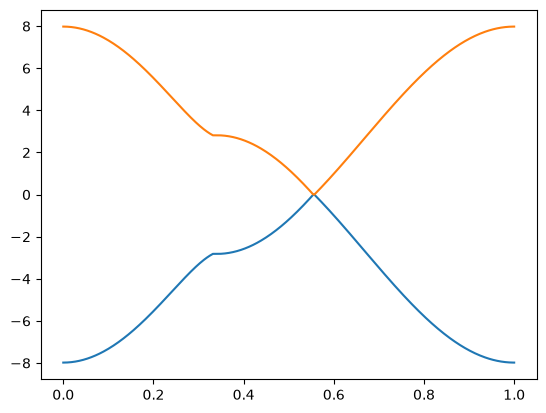

In [4]:
### Plotting energies along a path in k-space

# # PATH GAMMA -> K -> M -> GAMMA
# ks = jnp.concatenate(
#     ( jnp.expand_dims(jnp.linspace(0,jnp.sqrt(3)*B_norm/3,200),1)*jnp.array([1,0,0]), # G -> K
#       jnp.expand_dims(
#           jnp.linspace(jnp.sqrt(3)*B_norm/3,(2/3)*jnp.sqrt(3)*B_norm/3,100),1)*jnp.array([1,0,0]) 
#           + jnp.expand_dims(jnp.linspace(0,B_norm/4,100),1)*jnp.array([0,1,0]), # K -> M
#       jnp.expand_dims(
#           jnp.linspace((2/3)*jnp.sqrt(3)*B_norm/3,0,150),1)*jnp.array([1,0,0]) 
#           + jnp.expand_dims(jnp.linspace(B_norm/4,0,150),1)*jnp.array([0,1,0]),  # M -> G          
#     )).T

# PATH GAMMA -> M -> K -> GAMMA
ks = jnp.concatenate(
    ( jnp.expand_dims(
          jnp.linspace(0,(2/3)*jnp.sqrt(3)*B_norm/3,150),1)*jnp.array([1,0,0]) 
          + jnp.expand_dims(jnp.linspace(0,B_norm/4,150),1)*jnp.array([0,1,0]),  # G -> M
      jnp.expand_dims(
          jnp.linspace((2/3)*jnp.sqrt(3)*B_norm/3,jnp.sqrt(3)*B_norm/3,100),1)*jnp.array([1,0,0]) 
          + jnp.expand_dims(jnp.linspace(B_norm/4,0,100),1)*jnp.array([0,1,0]), # M -> K
        jnp.expand_dims(jnp.linspace(jnp.sqrt(3)*B_norm/3,0,200),1)*jnp.array([1,0,0]), # K -> G
    )).T

# # get eigenvalues along path
energies, eigenvectors = bulk.get_eigenbasis(ks)
plt.plot(jnp.linspace(0, 1, ks.shape[1]), energies)
plt.show()